# Internet use in Kazakhstan and neighbouring countries, 2000 to 2024

MYP Personal Project: data analysis and visualisation using Python.

**Research question:** How fast did internet use grow in Kazakhstan, and how does it compare with Kyrgyzstan, Uzbekistan, Turkmenistan, Russia, China and the world average?

**Data:** World Bank, World Development Indicators, indicator IT.NET.USER.ZS, *Individuals using the Internet (% of population)*. The series were copied from the FRED mirror of the World Bank data (see `data/README.md`).

## 1. Setup

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_RAW = Path("data/raw")
DATA_CLEAN = Path("data/clean")
FIG_DIR = Path("figures")
DATA_CLEAN.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

NAMES = {
    "KAZ": "Kazakhstan", "KGZ": "Kyrgyzstan", "UZB": "Uzbekistan",
    "TKM": "Turkmenistan", "RUS": "Russia", "CHN": "China", "WLD": "World",
}
# Okabe-Ito colour-blind safe palette. Kazakhstan always gets the same strong colour.
COLORS = {
    "Kazakhstan": "#0072B2", "Kyrgyzstan": "#E69F00", "Uzbekistan": "#009E73",
    "Turkmenistan": "#CC79A7", "Russia": "#D55E00", "China": "#56B4E9", "World": "#444444",
}
SOURCE = "Source: World Bank, World Development Indicators (IT.NET.USER.ZS)"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
})

## 2. Load the raw data

Each file in `data/raw` has two columns, `year` and `value`. An empty value means the World Bank reports no number for that year.

In [2]:
frames = []
for code_, name in NAMES.items():
    df = pd.read_csv(DATA_RAW / f"{code_}.csv")
    df["code"] = code_
    df["country"] = name
    frames.append(df)

raw = pd.concat(frames, ignore_index=True)
print(raw.shape)
raw.head()

(238, 4)


,year,value,code,country
0,1990,0.000000,KAZ,Kazakhstan
1,1991,NaN,KAZ,Kazakhstan
2,1992,NaN,KAZ,Kazakhstan
3,1993,NaN,KAZ,Kazakhstan
4,1994,0.000521,KAZ,Kazakhstan


## 3. Data quality checks and cleaning

Checks: number of rows, missing values, impossible values (below 0 or above 100), duplicates, and the first and last year with a real value for each country.

In [3]:
report = (
    raw.groupby("country")
    .agg(rows=("year", "size"),
         missing=("value", lambda s: s.isna().sum()),
         first_year=("year", lambda s: s[raw.loc[s.index, "value"].notna()].min()),
         last_year=("year", lambda s: s[raw.loc[s.index, "value"].notna()].max()),
         min_value=("value", "min"), max_value=("value", "max"))
)
print("Duplicate country-year rows:", raw.duplicated(["code", "year"]).sum())
print("Values outside 0-100:", ((raw["value"] < 0) | (raw["value"] > 100)).sum())
report

Duplicate country-year rows: 0
Values outside 0-100: 0


,rows,missing,first_year,last_year,min_value,max_value
country,,,,,,
China,36,2,1990,2025,0.000000,92.000000
Kazakhstan,35,3,1990,2024,0.000000,93.391700
Kyrgyzstan,35,7,1990,2024,0.000000,92.028603
Russia,35,1,1990,2024,0.000000,94.364954
Turkmenistan,28,8,1990,2017,0.000000,21.251000
Uzbekistan,35,4,1990,2024,0.000000,89.505501
World,34,0,1990,2023,0.048825,67.400000


**What I found.** Early years (1990 to the late 1990s) are either zero or missing for several countries, and Turkmenistan stops in 2017 while the world average stops in 2023. A value of exactly 0.0 in 1990 is a placeholder for "almost nobody online", not a measurement of a precise zero, so I do not use 1990 to 1999 for growth calculations.

**Cleaning decisions**
1. Drop rows with no value (they are not zeros).
2. Use the window **2000 to 2024**, where every country that has data reports real numbers.
3. Keep each country's own last year. I do not fill the gaps (Turkmenistan after 2017, World after 2023) because inventing values would be dishonest.

In [4]:
clean = (
    raw.dropna(subset=["value"])
    .query("2000 <= year <= 2024")
    .sort_values(["country", "year"])
    .reset_index(drop=True)
)
clean["value"] = clean["value"].round(2)
clean.to_csv(DATA_CLEAN / "internet_users_2000_2024.csv", index=False)

wide = clean.pivot(index="year", columns="country", values="value")
print(clean.shape)
wide.tail(8)

(167, 4)


country,China,Kazakhstan,Kyrgyzstan,Russia,Turkmenistan,Uzbekistan,World
year,,,,,,,
2017,54.30,76.43,50.81,76.01,21.25,48.70,45.4
2018,65.36,78.90,62.80,80.86,NaN,55.20,48.6
2019,64.08,81.88,64.10,82.64,NaN,70.40,53.2
2020,70.05,85.94,72.00,84.99,NaN,71.10,59.3
2021,73.05,90.92,77.12,88.21,NaN,76.59,62.2
2022,75.61,92.30,84.19,90.42,NaN,83.90,64.4
2023,90.60,92.88,91.04,92.24,NaN,89.01,67.4
2024,92.00,93.39,92.03,94.36,NaN,89.51,NaN


## 4. Descriptive analysis

I calculate the level in 2010 and in the last common years, the growth in percentage points (pp), and the first year each country passed 10%, 50% and 90% of the population online.

In [5]:
def value_at(country, year):
    s = wide[country].dropna()
    return s.get(year)

def first_year_above(country, threshold):
    s = wide[country].dropna()
    hit = s[s >= threshold]
    return int(hit.index[0]) if len(hit) else None

rows = []
for c in wide.columns:
    s = wide[c].dropna()
    rows.append({
        "country": c,
        "last_year": int(s.index[-1]),
        "last_value": s.iloc[-1],
        "value_2010": value_at(c, 2010),
        "value_2017": value_at(c, 2017),
        "growth_2010_2017_pp": (value_at(c, 2017) - value_at(c, 2010)),
        "first_year_over_10": first_year_above(c, 10),
        "first_year_over_50": first_year_above(c, 50),
        "first_year_over_90": first_year_above(c, 90),
    })
summary = pd.DataFrame(rows).set_index("country").round(1)
summary.to_csv(DATA_CLEAN / "summary_table.csv")
summary

,last_year,last_value,value_2010,value_2017,growth_2010_2017_pp,first_year_over_10,first_year_over_50,first_year_over_90
country,,,,,,,,
China,2024,92.0,34.3,54.3,20.0,2006,2015.0,2023.0
Kazakhstan,2024,93.4,31.6,76.4,44.8,2008,2011.0,2021.0
Kyrgyzstan,2024,92.0,16.3,50.8,34.5,2005,2017.0,2023.0
Russia,2024,94.4,49.0,76.0,27.0,2004,2011.0,2022.0
Turkmenistan,2017,21.2,3.0,21.2,18.2,2014,NaN,NaN
Uzbekistan,2024,89.5,15.9,48.7,32.8,2009,2018.0,NaN
World,2023,67.4,28.5,45.4,16.9,2002,2019.0,NaN


### Largest one-year jumps in Kazakhstan

The change from one year to the next shows when growth was fastest.

In [6]:
kaz_change = wide["Kazakhstan"].diff().dropna().round(1)
kaz_change.sort_values(ascending=False).head(5).rename("change_pp").to_frame()

,change_pp
year,
2011,19.0
2010,13.4
2012,11.3
2009,7.2
2008,7.0


## 5. Visualisation

### Chart 1: line chart, Kazakhstan compared with the world

Two lines only, so the comparison is easy to read. Y axis is a percentage from 0 to 100.

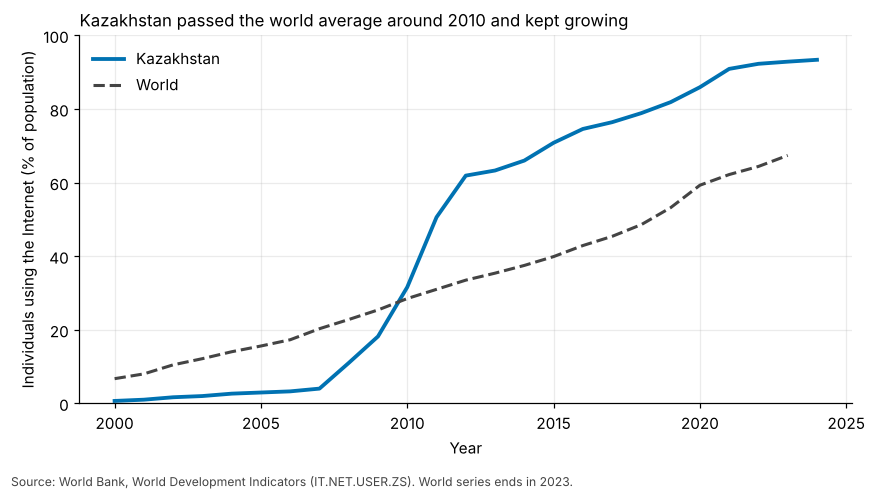

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for c in ["Kazakhstan", "World"]:
    s = wide[c].dropna()
    ax.plot(s.index, s.values, label=c, color=COLORS[c], lw=2.5 if c == "Kazakhstan" else 2,
            ls="-" if c == "Kazakhstan" else "--")
ax.set_ylim(0, 100)
ax.set_xlabel("Year")
ax.set_ylabel("Individuals using the Internet (% of population)")
ax.set_title("Kazakhstan passed the world average around 2010 and kept growing", loc="left", fontsize=11)
ax.legend(frameon=False)
fig.text(0.01, 0.005, SOURCE + ". World series ends in 2023.", fontsize=8, color="#444444")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG_DIR / "01_kazakhstan_vs_world_line.png", dpi=160)
plt.show()

### Chart 2: small multiples, one panel per country

A single line chart with seven lines would be unreadable (guidance: at most four lines). Every panel uses the same scale, so the panels can be compared fairly. Kazakhstan is shown as a grey reference line in the other panels.

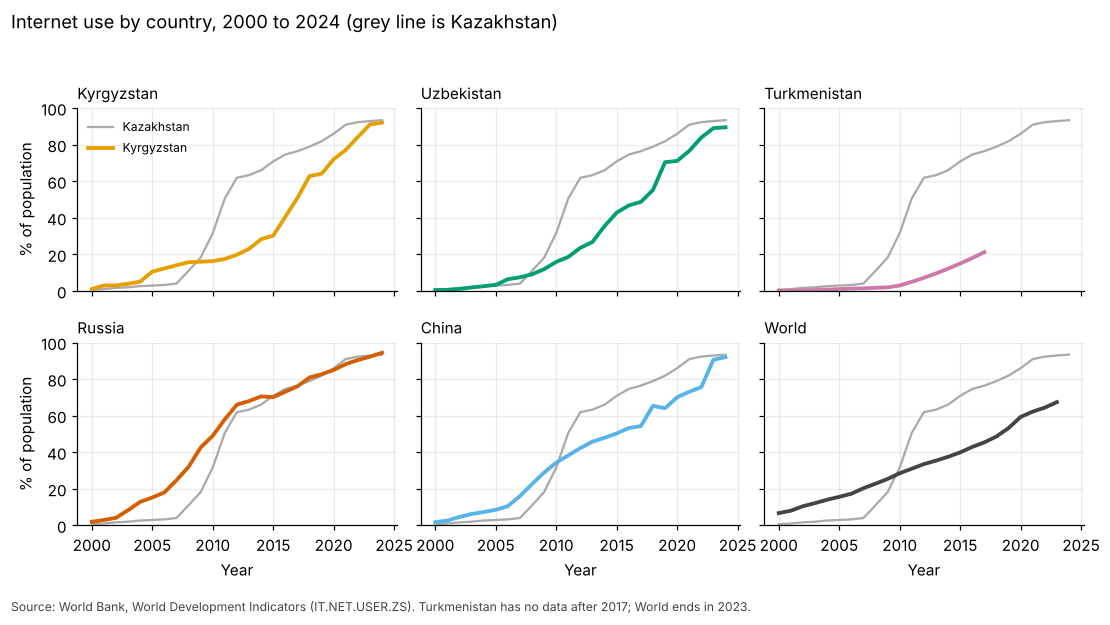

In [8]:
others = ["Kyrgyzstan", "Uzbekistan", "Turkmenistan", "Russia", "China", "World"]
fig, axes = plt.subplots(2, 3, figsize=(10, 5.6), sharex=True, sharey=True)
for ax, c in zip(axes.ravel(), others):
    k = wide["Kazakhstan"].dropna()
    ax.plot(k.index, k.values, color="#AAAAAA", lw=1.5, label="Kazakhstan")
    s = wide[c].dropna()
    ax.plot(s.index, s.values, color=COLORS[c], lw=2.5, label=c)
    ax.set_title(c, loc="left", fontsize=10)
    ax.set_ylim(0, 100)
for ax in axes[1]:
    ax.set_xlabel("Year")
for ax in axes[:, 0]:
    ax.set_ylabel("% of population")
axes[0, 0].legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle("Internet use by country, 2000 to 2024 (grey line is Kazakhstan)", x=0.01, ha="left", fontsize=12)
fig.text(0.01, 0.005, SOURCE + ". Turkmenistan has no data after 2017; World ends in 2023.", fontsize=8, color="#444444")
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
fig.savefig(FIG_DIR / "02_small_multiples_line.png", dpi=160)
plt.show()

### Chart 3: bar chart, ranking in 2017

2017 is the last year in which all six countries and the world have a value, so it is the only fair year for a full ranking. Bars start at zero and are sorted by value.

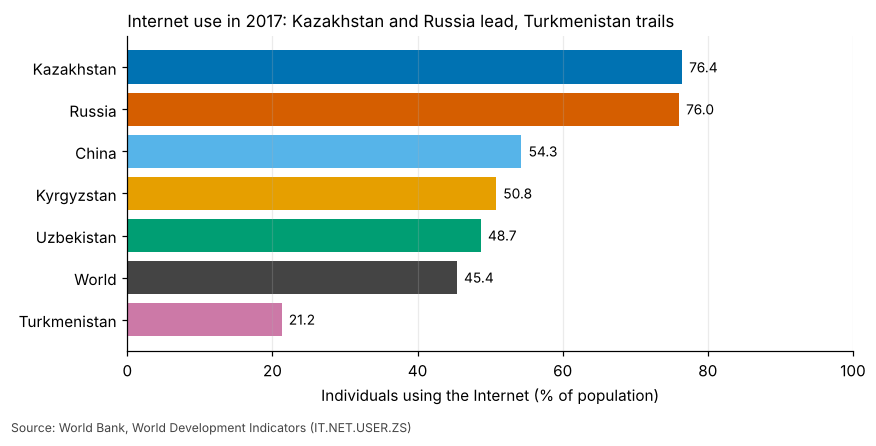

In [9]:
y = 2017
bar = wide.loc[y].dropna().sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(bar.index, bar.values, color=[COLORS[c] for c in bar.index])
for i, v in enumerate(bar.values):
    ax.text(v + 1, i, f"{v:.1f}", va="center", fontsize=9)
ax.set_xlim(0, 100)
ax.set_xlabel("Individuals using the Internet (% of population)")
ax.set_title(f"Internet use in {y}: Kazakhstan and Russia lead, Turkmenistan trails", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
fig.text(0.01, 0.005, SOURCE, fontsize=8, color="#444444")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG_DIR / "03_ranking_2017_bar.png", dpi=160)
plt.show()

### Chart 4: bar chart, ranking in 2023

Turkmenistan has no value after 2017, so it is left out here rather than guessed. 2023 is used because it is the last year the world average is available.

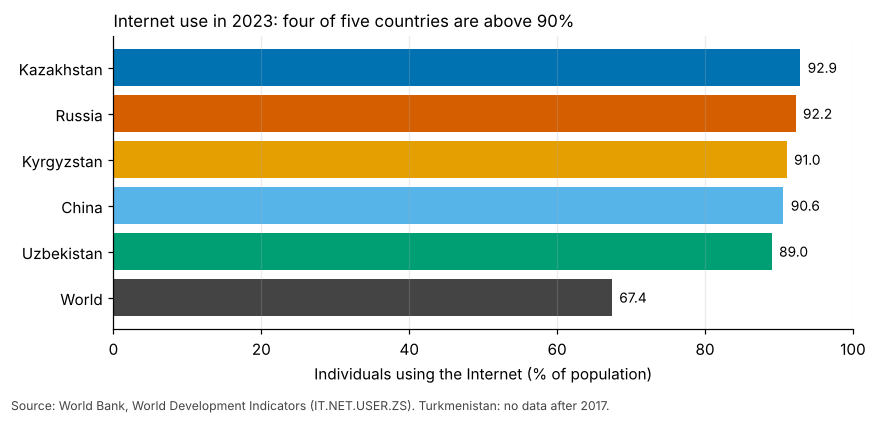

In [10]:
y = 2023
bar = wide.loc[y].dropna().sort_values()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(bar.index, bar.values, color=[COLORS[c] for c in bar.index])
for i, v in enumerate(bar.values):
    ax.text(v + 1, i, f"{v:.1f}", va="center", fontsize=9)
ax.set_xlim(0, 100)
ax.set_xlabel("Individuals using the Internet (% of population)")
ax.set_title(f"Internet use in {y}: four of five countries are above 90%", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
fig.text(0.01, 0.005, SOURCE + ". Turkmenistan: no data after 2017.", fontsize=8, color="#444444")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG_DIR / "04_ranking_2023_bar.png", dpi=160)
plt.show()

### Chart 5: scatter plot, starting level and later growth

Does a country that started lower grow more in the next years? Each point is a country: its level in 2010 against its growth from 2010 to 2017 in percentage points.

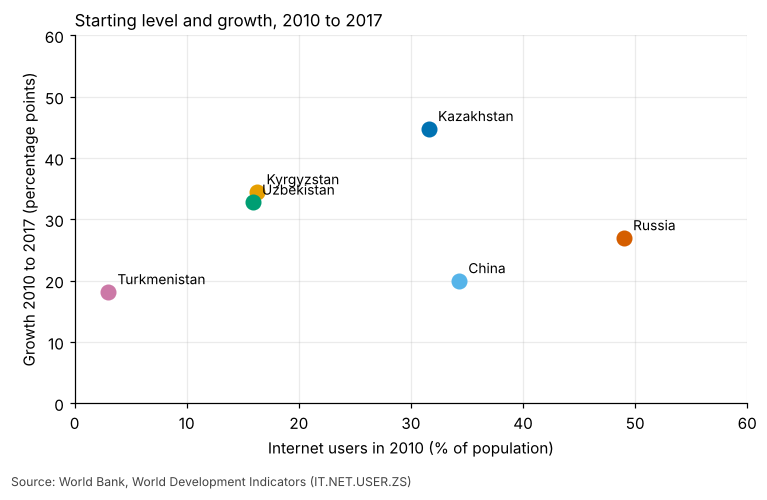

In [11]:
sc = summary.drop(index="World")[["value_2010", "growth_2010_2017_pp"]]
fig, ax = plt.subplots(figsize=(7, 4.5))
for c, r in sc.iterrows():
    ax.scatter(r["value_2010"], r["growth_2010_2017_pp"], s=90, color=COLORS[c], zorder=3)
    ax.annotate(c, (r["value_2010"], r["growth_2010_2017_pp"]), xytext=(6, 5), textcoords="offset points", fontsize=9)
ax.set_xlim(0, 60)
ax.set_ylim(0, 60)
ax.set_xlabel("Internet users in 2010 (% of population)")
ax.set_ylabel("Growth 2010 to 2017 (percentage points)")
ax.set_title("Starting level and growth, 2010 to 2017", loc="left", fontsize=11)
fig.text(0.01, 0.005, SOURCE, fontsize=8, color="#444444")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG_DIR / "05_start_vs_growth_scatter.png", dpi=160)
plt.show()

### Chart 6: histogram, size of yearly changes

How big is a typical one-year change, and how often are changes very large? All countries are pooled, years 2001 to 2024.

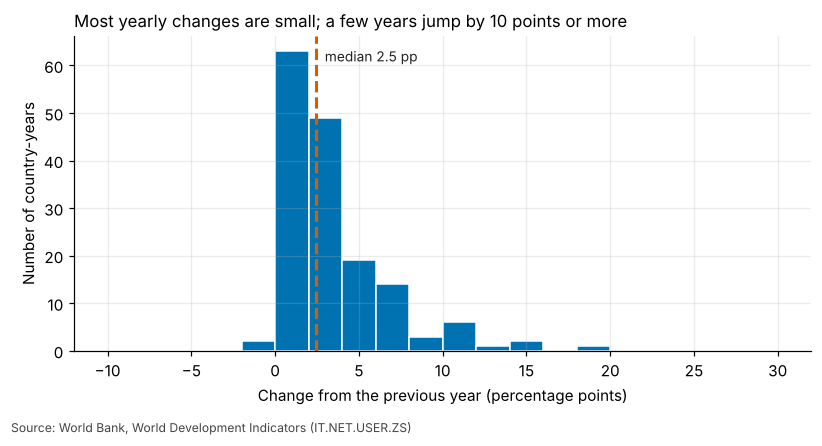

Share of country-years with a change of 10 pp or more: 5.7 %


In [12]:
changes = wide.diff().stack().rename("change_pp")
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.hist(changes, bins=range(-10, 31, 2), color="#0072B2", edgecolor="white")
ax.axvline(changes.median(), color="#D55E00", lw=2, ls="--")
ax.text(changes.median() + 0.5, ax.get_ylim()[1] * 0.92, f"median {changes.median():.1f} pp", color="#222222", fontsize=9)
ax.set_xlabel("Change from the previous year (percentage points)")
ax.set_ylabel("Number of country-years")
ax.set_title("Most yearly changes are small; a few years jump by 10 points or more", loc="left", fontsize=11)
fig.text(0.01, 0.005, SOURCE, fontsize=8, color="#444444")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG_DIR / "06_yearly_change_histogram.png", dpi=160)
plt.show()
print("Share of country-years with a change of 10 pp or more:", round((changes >= 10).mean() * 100, 1), "%")

## 6. Conclusions

In [13]:
k = summary.loc["Kazakhstan"]
print(f"1. Kazakhstan passed 10% in {k.first_year_over_10:.0f}, 50% in {k.first_year_over_50:.0f} and 90% in {k.first_year_over_90:.0f}.")
others_ = summary.drop(index=["Kazakhstan", "World"])
print("2. First year over 50% by country:")
print(others_["first_year_over_50"].sort_values().to_string())
print(f"3. In 2023 Kazakhstan was at {wide.loc[2023, 'Kazakhstan']:.1f}% and the world at {wide.loc[2023, 'World']:.1f}%, "
      f"a gap of {wide.loc[2023, 'Kazakhstan'] - wide.loc[2023, 'World']:.1f} pp.")

1. Kazakhstan passed 10% in 2008, 50% in 2011 and 90% in 2021.
2. First year over 50% by country:
country
Russia          2011.0
China           2015.0
Kyrgyzstan      2017.0
Uzbekistan      2018.0
Turkmenistan       NaN
3. In 2023 Kazakhstan was at 92.9% and the world at 67.4%, a gap of 25.5 pp.


Written conclusions (checked against the numbers above) are in `README.md`.

**Limitations.** (1) The indicator counts people who used the internet in the last three months, as reported by each country; methods differ between countries and years. (2) Turkmenistan has no data after 2017 and the world average ends in 2023. (3) A percentage of the population says nothing about speed, price or quality of access. (4) Large jumps (for example Kazakhstan in 2010 and 2011) may partly reflect changes in survey method; I have not verified this.